# **I. IMPORTING THE NECESSARY LIBRARIES**

In [1]:
import pandas as pd #Library for working with datasets
import numpy as np #Library for working with arrays
import matplotlib.pyplot as plt #Library for working with visualizing data
from sklearn.model_selection import train_test_split #For splitting data into training and testing
from sklearn.preprocessing import StandardScaler #For Feature Scaling
from sklearn.linear_model import LinearRegression #For Linear Regression model
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score #For calculating metrics

****

# **II. LOADING THE DATAFRAME**

In [2]:
# Initialize the original dataframe
df = pd.read_csv("/kaggle/input/datasets/margielynatienza/cats-dataset/cat_age_prediction_dataset.csv")

if df is not None: #Checks if the dataframe is loaded
    print("Loaded: Cat Age Prediction Dataset") 
    print(f"Rows: {len(df)} || Columns: {len(df.columns)}")

Loaded: Cat Age Prediction Dataset
Rows: 500000 || Columns: 12


****

# **III. ANALYZING THE ORIGINAL DATAFRAME**

In [3]:
df #check original dataset

,cat_id,weight_kg,body_measurements,health_statistics,muscle_score,breed,coat_type,eye_color,vaccinated,neutered,indoor_or_outdoor,cat_age
0,104242,5.665,60.891,81.70,10.893,Siamese,Short,Amber,1,0,1,10.1
1,199677,6.000,30.429,NaN,8.832,Siamese,Short,Amber,1,1,0,5.5
2,140200,4.704,19.774,82.80,16.674,Siamese,Short,Amber,1,1,1,6.3
3,132815,5.087,53.034,73.06,33.158,Domestic Shorthair,Hairless,Amber,1,1,1,13.8
4,408698,3.918,44.104,91.18,24.691,Maine Coon,Long,Green,1,1,0,11.0
...,...,...,...,...,...,...,...,...,...,...,...,...
499995,259179,3.439,62.931,88.27,11.629,Siamese,Short,Green,1,1,0,13.0
499996,365839,3.792,41.884,79.92,14.649,Siamese,Long,Blue,1,1,1,6.5
499997,131933,3.943,NaN,100.00,15.588,Maine Coon,Hairless,Blue,1,1,1,10.8
499998,146868,3.343,58.158,58.38,13.517,Persian,NaN,Blue,1,1,0,4.9


In [4]:
df.columns #print all column names

Index(['cat_id', 'weight_kg', 'body_measurements', 'health_statistics',
       'muscle_score', 'breed', 'coat_type', 'eye_color', 'vaccinated',
       'neutered', 'indoor_or_outdoor', 'cat_age'],
      dtype='object')

In [5]:
df.info() #print summary of information

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500000 entries, 0 to 499999
Data columns (total 12 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   cat_id             500000 non-null  int64  
 1   weight_kg          482539 non-null  float64
 2   body_measurements  482543 non-null  float64
 3   health_statistics  482520 non-null  float64
 4   muscle_score       482538 non-null  float64
 5   breed              482483 non-null  object 
 6   coat_type          482416 non-null  object 
 7   eye_color          482510 non-null  object 
 8   vaccinated         500000 non-null  int64  
 9   neutered           500000 non-null  int64  
 10  indoor_or_outdoor  500000 non-null  int64  
 11  cat_age            500000 non-null  float64
dtypes: float64(5), int64(4), object(3)
memory usage: 45.8+ MB


In [6]:
df.describe() #generates description

,cat_id,weight_kg,body_measurements,health_statistics,muscle_score,vaccinated,neutered,indoor_or_outdoor,cat_age
count,500000.000000,482539.000000,482543.000000,482520.000000,482538.000000,500000.000000,500000.000000,500000.00000,500000.000000
mean,225070.332990,4.505663,40.027886,74.922043,15.826957,0.719694,0.600532,0.54883,8.146151
std,129888.910441,1.118951,12.337051,10.065749,8.090754,0.449149,0.489790,0.49761,3.465830
min,1.000000,0.500000,11.211000,14.610000,5.007000,0.000000,0.000000,0.00000,0.200000
25%,112671.750000,3.756000,31.063000,68.230000,9.911000,0.000000,0.000000,0.00000,5.700000
50%,225100.500000,4.501000,38.365000,74.980000,13.894000,1.000000,1.000000,1.00000,8.000000
75%,337567.250000,5.244000,47.127000,81.710000,19.668000,1.000000,1.000000,1.00000,10.300000
max,450000.000000,16.558000,150.985000,100.000000,187.337000,1.000000,1.000000,1.00000,20.000000


In [7]:
df.shape #prints number of rows and columns

(500000, 12)

In [8]:
df.head(5) #prints the first 5 rows

,cat_id,weight_kg,body_measurements,health_statistics,muscle_score,breed,coat_type,eye_color,vaccinated,neutered,indoor_or_outdoor,cat_age
0,104242,5.665,60.891,81.70,10.893,Siamese,Short,Amber,1,0,1,10.1
1,199677,6.000,30.429,NaN,8.832,Siamese,Short,Amber,1,1,0,5.5
2,140200,4.704,19.774,82.80,16.674,Siamese,Short,Amber,1,1,1,6.3
3,132815,5.087,53.034,73.06,33.158,Domestic Shorthair,Hairless,Amber,1,1,1,13.8
4,408698,3.918,44.104,91.18,24.691,Maine Coon,Long,Green,1,1,0,11.0


In [9]:
df.tail(5) #prints the last 5 rows

,cat_id,weight_kg,body_measurements,health_statistics,muscle_score,breed,coat_type,eye_color,vaccinated,neutered,indoor_or_outdoor,cat_age
499995,259179,3.439,62.931,88.27,11.629,Siamese,Short,Green,1,1,0,13.0
499996,365839,3.792,41.884,79.92,14.649,Siamese,Long,Blue,1,1,1,6.5
499997,131933,3.943,NaN,100.00,15.588,Maine Coon,Hairless,Blue,1,1,1,10.8
499998,146868,3.343,58.158,58.38,13.517,Persian,NaN,Blue,1,1,0,4.9
499999,121959,3.446,27.223,65.79,13.271,Domestic Shorthair,Long,Green,0,0,1,4.7


****

# **IV. DUPLICATING THE DATAFRAME**

In [10]:
data = df.copy() #independent copy of original dataset for data manipulation

In [11]:
data #print the duplicated dataset

,cat_id,weight_kg,body_measurements,health_statistics,muscle_score,breed,coat_type,eye_color,vaccinated,neutered,indoor_or_outdoor,cat_age
0,104242,5.665,60.891,81.70,10.893,Siamese,Short,Amber,1,0,1,10.1
1,199677,6.000,30.429,NaN,8.832,Siamese,Short,Amber,1,1,0,5.5
2,140200,4.704,19.774,82.80,16.674,Siamese,Short,Amber,1,1,1,6.3
3,132815,5.087,53.034,73.06,33.158,Domestic Shorthair,Hairless,Amber,1,1,1,13.8
4,408698,3.918,44.104,91.18,24.691,Maine Coon,Long,Green,1,1,0,11.0
...,...,...,...,...,...,...,...,...,...,...,...,...
499995,259179,3.439,62.931,88.27,11.629,Siamese,Short,Green,1,1,0,13.0
499996,365839,3.792,41.884,79.92,14.649,Siamese,Long,Blue,1,1,1,6.5
499997,131933,3.943,NaN,100.00,15.588,Maine Coon,Hairless,Blue,1,1,1,10.8
499998,146868,3.343,58.158,58.38,13.517,Persian,NaN,Blue,1,1,0,4.9


****

# **V. DATA CLEANING**

**V.I. DUPLICATING THE DATA SET**

In [12]:
data.duplicated() #check for duplicate records

0         False
1         False
2         False
3         False
4         False
          ...  
499995    False
499996    False
499997    False
499998    False
499999    False
Length: 500000, dtype: bool

In [13]:
data.duplicated().sum() #gets the amount of duplicated rows

np.int64(50000)

In [14]:
data = data.drop_duplicates() #deletes all the duplicated rows

In [15]:
data #check the dataset for differences

,cat_id,weight_kg,body_measurements,health_statistics,muscle_score,breed,coat_type,eye_color,vaccinated,neutered,indoor_or_outdoor,cat_age
0,104242,5.665,60.891,81.70,10.893,Siamese,Short,Amber,1,0,1,10.1
1,199677,6.000,30.429,NaN,8.832,Siamese,Short,Amber,1,1,0,5.5
2,140200,4.704,19.774,82.80,16.674,Siamese,Short,Amber,1,1,1,6.3
3,132815,5.087,53.034,73.06,33.158,Domestic Shorthair,Hairless,Amber,1,1,1,13.8
4,408698,3.918,44.104,91.18,24.691,Maine Coon,Long,Green,1,1,0,11.0
...,...,...,...,...,...,...,...,...,...,...,...,...
499995,259179,3.439,62.931,88.27,11.629,Siamese,Short,Green,1,1,0,13.0
499996,365839,3.792,41.884,79.92,14.649,Siamese,Long,Blue,1,1,1,6.5
499997,131933,3.943,NaN,100.00,15.588,Maine Coon,Hairless,Blue,1,1,1,10.8
499998,146868,3.343,58.158,58.38,13.517,Persian,NaN,Blue,1,1,0,4.9


In [16]:
data.duplicated().sum() #confirming no more duplicates

np.int64(0)

**V.II. REMOVE IRRELEVANT COLUMNS**

In [17]:
irrelevant_columns = data[["cat_id", "coat_type", "eye_color"]] #create array of columns to remove

#loop to remove columns
for i in irrelevant_columns:
    data = data.drop(i, axis = "columns")

In [18]:
data #check data to see

,weight_kg,body_measurements,health_statistics,muscle_score,breed,vaccinated,neutered,indoor_or_outdoor,cat_age
0,5.665,60.891,81.70,10.893,Siamese,1,0,1,10.1
1,6.000,30.429,NaN,8.832,Siamese,1,1,0,5.5
2,4.704,19.774,82.80,16.674,Siamese,1,1,1,6.3
3,5.087,53.034,73.06,33.158,Domestic Shorthair,1,1,1,13.8
4,3.918,44.104,91.18,24.691,Maine Coon,1,1,0,11.0
...,...,...,...,...,...,...,...,...,...
499995,3.439,62.931,88.27,11.629,Siamese,1,1,0,13.0
499996,3.792,41.884,79.92,14.649,Siamese,1,1,1,6.5
499997,3.943,NaN,100.00,15.588,Maine Coon,1,1,1,10.8
499998,3.343,58.158,58.38,13.517,Persian,1,1,0,4.9


In [19]:
data.shape #check the shape of the data

(450000, 9)

**V.III. CHECKING FOR MISSING VALUES**

In [20]:
data.count() #checks name of each column and amount of non-missing entries

weight_kg            434250
body_measurements    434250
health_statistics    434250
muscle_score         434250
breed                434250
vaccinated           450000
neutered             450000
indoor_or_outdoor    450000
cat_age              450000
dtype: int64

In [21]:
data.isnull().sum() #checks number of missing values in each column

weight_kg            15750
body_measurements    15750
health_statistics    15750
muscle_score         15750
breed                15750
vaccinated               0
neutered                 0
indoor_or_outdoor        0
cat_age                  0
dtype: int64

**V.IV. FIXING INCONSISTENT FORMATS**

In [22]:
data["breed"].value_counts() #display and count all the common given values

breed
Domestic Shorthair     144479
Siamese                104424
Persian                 84285
Maine Coon              82163
Domestic-Shorthair       1126
domestic shorthair       1121
Domestic_Shorthair       1108
Domestic Shorthair       1079
#Domestic Shorthair      1069
 Domestic Shorthair      1059
DOMESTIC SHORTHAIR       1044
 Siamese                  818
#Siamese                  811
siamese                   802
Siamese                   769
SIAMESE                   739
Persian                   664
MAINE COON                650
persian                   634
#Maine Coon               629
PERSIAN                   615
Maine Coon                613
maine coon                608
Maine-Coon                601
 Maine Coon               596
 Persian                  590
#Persian                  585
Maine_Coon                569
Name: count, dtype: int64

In [23]:
data["breed"] = data["breed"].str.title() #converts all the values into Title case

In [24]:
data["breed"] = data["breed"].str.strip("#") #strips values that contain the '#' char
data["breed"] = data["breed"].str.strip() #strips both right and left whitespaces

In [25]:
data["breed"] = data["breed"].str.replace("-", " ") #removes '-' between words
data["breed"] = data["breed"].str.replace("_", " ") #removes '_' between words

In [26]:
data["breed"].value_counts() #confirm the desired values

breed
Domestic Shorthair    152085
Siamese               108363
Persian                87373
Maine Coon             86429
Name: count, dtype: int64

****

# **VI. DATA SPLITTING**

**VI.I. FEATURE LABEL SEPARATION**

In [27]:
X = data.drop("cat_age", axis = "columns") #stores a version of the data without the target variable as 'X'

In [28]:
y = data["cat_age"] #stores the target variable as 'y'

In [29]:
X.head() #displays X's first 5 rows

,weight_kg,body_measurements,health_statistics,muscle_score,breed,vaccinated,neutered,indoor_or_outdoor
0,5.665,60.891,81.70,10.893,Siamese,1,0,1
1,6.000,30.429,NaN,8.832,Siamese,1,1,0
2,4.704,19.774,82.80,16.674,Siamese,1,1,1
3,5.087,53.034,73.06,33.158,Domestic Shorthair,1,1,1
4,3.918,44.104,91.18,24.691,Maine Coon,1,1,0


In [30]:
y.head() #displays y's first 5 rows

0    10.1
1     5.5
2     6.3
3    13.8
4    11.0
Name: cat_age, dtype: float64

**VI.II. TRAIN TEST SPLIT**

In [31]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42) #splits X and Y into training and testing data

**VI.III. ANALYZING SPLITTED RESULTS**

In [32]:
data.shape #check the shape of the entire dataset

(450000, 9)

In [33]:
X_train.shape #check the shape of the training features

(360000, 8)

In [34]:
X_test.shape #check the shape of the testing features

(90000, 8)

In [35]:
y_train.shape #check the shape of the training target variable

(360000,)

In [36]:
y_test.shape #check the shape of the testing target variable

(90000,)

In [37]:
print("Training Cat Characteristics:", len(X_train)) #check amount of rows of training features
print("Training Cat Age:", len(y_train)) #check amount of rows of the training target variable

print("Test Cat Characteristics:", len(X_test)) #check amount of rows of testing features
print("Test Cat Age:", len(y_test)) #check amount of rows of the testing target variable

Training Cat Characteristics: 360000
Training Cat Age: 360000
Test Cat Characteristics: 90000
Test Cat Age: 90000


****

# **VII. DATA PREPROCESSING**

In [38]:
# create copies so original training data remain unchanged
X_train_prepared = X_train.copy()
X_test_prepared = X_test.copy()

**VII.I. HANDLING MISSING VALUES**

In [39]:
X_train_prepared.isnull().sum() #check missing values in training data

weight_kg            12718
body_measurements    12600
health_statistics    12666
muscle_score         12677
breed                12706
vaccinated               0
neutered                 0
indoor_or_outdoor        0
dtype: int64

In [40]:
X_test_prepared.isnull().sum() #check missing values in testing data

weight_kg            3032
body_measurements    3150
health_statistics    3084
muscle_score         3073
breed                3044
vaccinated              0
neutered                0
indoor_or_outdoor       0
dtype: int64

In [41]:
# Mean Imputation on 'weight_kg' column
weight_mean = X_train_prepared["weight_kg"].mean()
X_train_prepared["weight_kg"] = X_train_prepared["weight_kg"].fillna(weight_mean) 
X_test_prepared["weight_kg"] = X_test_prepared["weight_kg"].fillna(weight_mean)

In [42]:
# Mean Imputation on 'body_measurements' column
body_measurements_mean = X_train_prepared["body_measurements"].mean()
X_train_prepared["body_measurements"] = X_train_prepared["body_measurements"].fillna(body_measurements_mean) 
X_test_prepared["body_measurements"] = X_test_prepared["body_measurements"].fillna(body_measurements_mean)

In [43]:
# Mean Imputation on 'health_statistics' column
heatlh_mean = X_train_prepared["health_statistics"].mean()
X_train_prepared["health_statistics"] = X_train_prepared["health_statistics"].fillna(heatlh_mean) 
X_test_prepared["health_statistics"] = X_test_prepared["health_statistics"].fillna(heatlh_mean)

In [44]:
# Mean Imputation on 'muscle_score' column
muscle_mean = X_train_prepared["muscle_score"].mean()
X_train_prepared["muscle_score"] = X_train_prepared["muscle_score"].fillna(muscle_mean) 
X_test_prepared["muscle_score"] = X_test_prepared["muscle_score"].fillna(muscle_mean)

In [45]:
# Mode Imputation on 'breed' column
breed_mode = X_train_prepared["breed"].mode()[0]
X_train_prepared["breed"] = X_train_prepared["breed"].fillna(breed_mode) 
X_test_prepared["breed"] = X_test_prepared["breed"].fillna(breed_mode)

In [46]:
X_train_prepared.isnull().sum() # confirm filled values in training data

weight_kg            0
body_measurements    0
health_statistics    0
muscle_score         0
breed                0
vaccinated           0
neutered             0
indoor_or_outdoor    0
dtype: int64

In [47]:
X_test_prepared.isnull().sum() # confirm filled values in testing data

weight_kg            0
body_measurements    0
health_statistics    0
muscle_score         0
breed                0
vaccinated           0
neutered             0
indoor_or_outdoor    0
dtype: int64

**VII.II. FEATURE SCALING**

In [48]:
numeric_columns = ["weight_kg", "body_measurements", "health_statistics", "muscle_score"] # All the columns you want to scale

In [49]:
scaler = StandardScaler() # create scaler object

In [50]:
X_train_prepared[numeric_columns] = scaler.fit_transform(X_train_prepared[numeric_columns]) #fit scaler on training data & transform training data

In [51]:
X_test_prepared[numeric_columns] = scaler.transform(X_test_prepared[numeric_columns]) # apply same scaling rule on testing data

In [52]:
X_train_prepared.head() # check the post-scaled training data

,weight_kg,body_measurements,health_statistics,muscle_score,breed,vaccinated,neutered,indoor_or_outdoor
45255,0.154371,-1.425649,0.172667,0.077823,Domestic Shorthair,1,1,1
193125,-1.017561,-0.985753,-1.186065,1.075118,Persian,1,1,0
49138,-0.697530,1.582122,1.645638,-0.649772,Maine Coon,1,1,1
186132,1.731797,-1.399807,0.248489,0.315274,Siamese,1,1,1
345409,1.044458,-0.093825,0.159525,0.426505,Maine Coon,0,1,1


**VII.III. CATEGORICAL ENCODING**

In [53]:
# converts column into numerical columns using one-hot encoding
X_train_prepared = pd.get_dummies(X_train_prepared, columns = ["breed"], dtype = int)
X_test_prepared = pd.get_dummies(X_test_prepared, columns = ["breed"], dtype = int)

In [54]:
X_train_prepared.head() # check categorically encoded column 

,weight_kg,body_measurements,health_statistics,muscle_score,vaccinated,neutered,indoor_or_outdoor,breed_Domestic Shorthair,breed_Maine Coon,breed_Persian,breed_Siamese
45255,0.154371,-1.425649,0.172667,0.077823,1,1,1,1,0,0,0
193125,-1.017561,-0.985753,-1.186065,1.075118,1,1,0,0,0,1,0
49138,-0.697530,1.582122,1.645638,-0.649772,1,1,1,0,1,0,0
186132,1.731797,-1.399807,0.248489,0.315274,1,1,1,0,0,0,1
345409,1.044458,-0.093825,0.159525,0.426505,0,1,1,0,1,0,0


In [55]:
X_test_prepared.head() # check categorically encoded column 

,weight_kg,body_measurements,health_statistics,muscle_score,vaccinated,neutered,indoor_or_outdoor,breed_Domestic Shorthair,breed_Maine Coon,breed_Persian,breed_Siamese
247386,-1.432147,-0.026371,0.023045,-1.254170e+00,1,1,0,0,0,1,0
41916,-1.484879,-0.060139,2.282544,-1.606357e-01,0,1,0,1,0,0,0
176248,-0.908459,-0.149390,-1.391290,-4.475309e-16,0,0,0,1,0,0,0
336968,0.177101,-1.289998,0.402155,-1.151254e+00,1,1,1,0,1,0,0
32863,0.233470,-1.578721,1.073434,6.119526e-02,0,0,1,1,0,0,0


****

# **VIII. MODEL TRAINING**

**VIII.I. MODEL SELECTION**

In [56]:
model = LinearRegression() # create Linear Regression model object

In [57]:
model # display selected model

LinearRegression()

In [58]:
X_train_prepared.head() # training features

,weight_kg,body_measurements,health_statistics,muscle_score,vaccinated,neutered,indoor_or_outdoor,breed_Domestic Shorthair,breed_Maine Coon,breed_Persian,breed_Siamese
45255,0.154371,-1.425649,0.172667,0.077823,1,1,1,1,0,0,0
193125,-1.017561,-0.985753,-1.186065,1.075118,1,1,0,0,0,1,0
49138,-0.697530,1.582122,1.645638,-0.649772,1,1,1,0,1,0,0
186132,1.731797,-1.399807,0.248489,0.315274,1,1,1,0,0,0,1
345409,1.044458,-0.093825,0.159525,0.426505,0,1,1,0,1,0,0


In [59]:
y_train.head() # training label

45255      5.1
193125     5.5
49138     12.5
186132     7.5
345409     9.6
Name: cat_age, dtype: float64

**VIII.II. TRAINING THE MODEL**

In [60]:
model.fit(X_train_prepared, y_train) # train the Linear Regression model

LinearRegression()

****

# **IX. MODEL EVALUATION**

**IX.I. GATHERING THE PREDICTIONS**

In [61]:
cat_age_prediction = model.predict(X_test_prepared) # predict target variable for testing data

In [62]:
cat_age_prediction[:10] # display 10 predicted values

array([ 4.34874259,  7.06819379,  6.02583393,  4.69922933,  6.34034918,
        9.33747302,  7.96871999,  6.43005783,  8.57656365, 10.85631726])

**IX.II. COMPARING THE RESULTS**

In [63]:
# comapring the actual values and predicted values
comparison = pd.DataFrame({
    "Original row": y_test.index,
    "Actual cat age": y_test.to_numpy(),
    "Predicted cat age": cat_age_prediction
})

comparison["Error"] = comparison["Actual cat age"] - comparison["Predicted cat age"] # formula for 'Error' column
comparison["Absolute error"] = comparison["Error"].abs() # formula for 'Absolute Error' column
display(comparison.head(10).round(2)) # display the comparison, showing 10 rows, and rounded off to two decimal points

,Original row,Actual cat age,Predicted cat age,Error,Absolute error
0,247386,4.8,4.35,0.45,0.45
1,41916,5.0,7.07,-2.07,2.07
2,176248,8.3,6.03,2.27,2.27
3,336968,1.4,4.70,-3.30,3.30
4,32863,3.7,6.34,-2.64,2.64
5,222981,7.5,9.34,-1.84,1.84
6,276184,5.8,7.97,-2.17,2.17
7,258310,3.2,6.43,-3.23,3.23
8,364072,6.3,8.58,-2.28,2.28
9,59495,8.9,10.86,-1.96,1.96


In [64]:
# compute the performance evaluation metrics
mse = mean_squared_error(y_test, cat_age_prediction) # Mean Squared Error (MSE)
mae = mean_absolute_error(y_test, cat_age_prediction) # Mean Absolute Error (MAE)
rmse = (mse)**(1/2) # Root Mean Squared Error (RMSE)
r2 = r2_score(y_test, cat_age_prediction) # R² Score
baseline_mae = mean_absolute_error(y_test, cat_age_prediction) # Baseline Mean Absolute Error

In [65]:
# evaluating the results of the model's training
print(f"We evaluated {len(y_test)} cat age based on various cat characteristics.")
print(f"Test MSE: {mse:,.2f} squared age units")
print(f"The average absolute error was {mae:,.2f} age units. ")
print(f"RMSE was {rmse:,.2f} age units; R² was {r2:.4f}.")

if mae < baseline_mae:
    print("Linear Regression has a lower test MAE than the training-mean baseline.")
else: 
    print("Linear Regression does not improve the test MAE over this baseline.")
print("The model still makes errors; inspect the individual predictions and plots.")

We evaluated 90000 cat age based on various cat characteristics.
Test MSE: 4.05 squared age units
The average absolute error was 1.60 age units. 
RMSE was 2.01 age units; R² was 0.6649.
Linear Regression does not improve the test MAE over this baseline.
The model still makes errors; inspect the individual predictions and plots.


****

# **X. VISUALIZATION**

**X.I. SCATTER PLOTS**

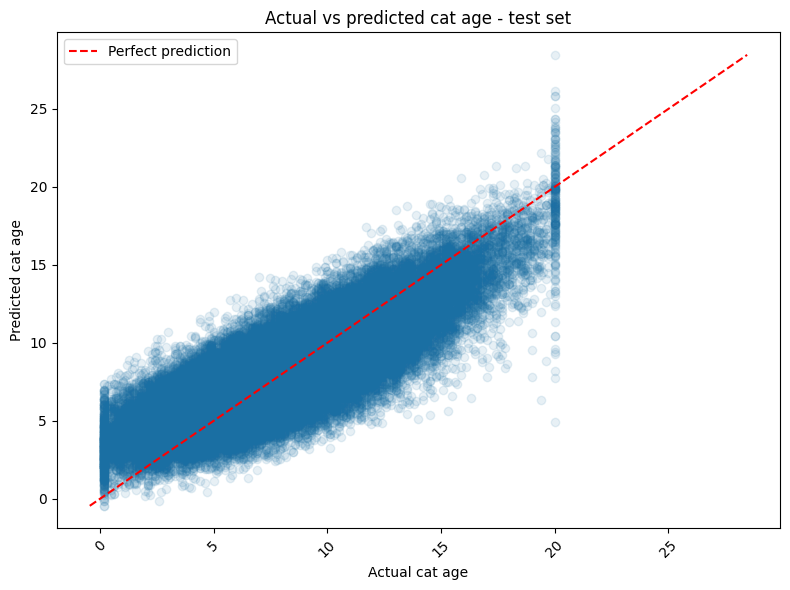

In [66]:
plt.figure(figsize=(8, 6)) # create figure size
plt.scatter(y_test, cat_age_prediction, alpha=0.1, color="#1A6FA3") # customizes the scatter points

lowest_age = min(y_test.min(), cat_age_prediction.min()) # gets the lowest age
highest_age = max(y_test.max(), cat_age_prediction.max()) # gets the highest age

# plotting the labeled data
plt.plot(
    [lowest_age, highest_age], [lowest_age, highest_age],
    "r--", label="Perfect prediction"
)

# sets the labels for the graph and the layout
plt.xlabel("Actual cat age")
plt.ylabel("Predicted cat age")
plt.title("Actual vs predicted cat age - test set")
plt.ticklabel_format(style="plain", axis="both")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()